# 📊 Uber Data India 2024 — Visual Insights & Operations Dashboard
**Role**: Business Analyst & Operations Intelligence Specialist  
**Methodology**: SQL-First Data Pipeline with Targeted Python (Matplotlib & Seaborn) Visualizations  
**Architecture**: Consumes analytical SQL tables (`uber_features` and `uber_cleaned`) from SQLite to communicate 7 critical operational insights.

---
### 📌 Visualizations Overview:
1. **Hourly Demand & Completion Profile**: 24-hour demand curve vs. completion efficiency.
2. **Modal Fulfillment & Friction Breakdown**: Completed vs. cancelled vs. incomplete rides by vehicle type.
3. **Monthly Booking & Revenue Trajectory**: Seasonality and cumulative gross booking value trend.
4. **Top Urban Pickup Hotspots**: Spatial distribution of highest-demand origin hubs.
5. **Vehicle Segment Unit Economics**: Fare per ride vs. trip distance across categories.
6. **Cancellation Root Cause Analysis**: Breakdown of customer-stated vs. driver-stated reasons.
7. **VTAT Delay vs. Customer Satisfaction Decay**: Impact of pickup wait times on star ratings.


In [1]:
import os
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Visual Theme Setup
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#CCCCCC'
plt.rcParams['axes.linewidth'] = 0.8

DB_PATH = '../data/processed/uber_analytics.db'
conn = sqlite3.connect(DB_PATH)
print("Connected to SQLite Analytical Database.")


Connected to SQLite Analytical Database.


## 1. Hourly Demand Profile & Completion Efficiency (Dual-Axis)
**Business Question**: What are the peak booking hours and how does operational fulfillment (completion rate) perform during rush windows?

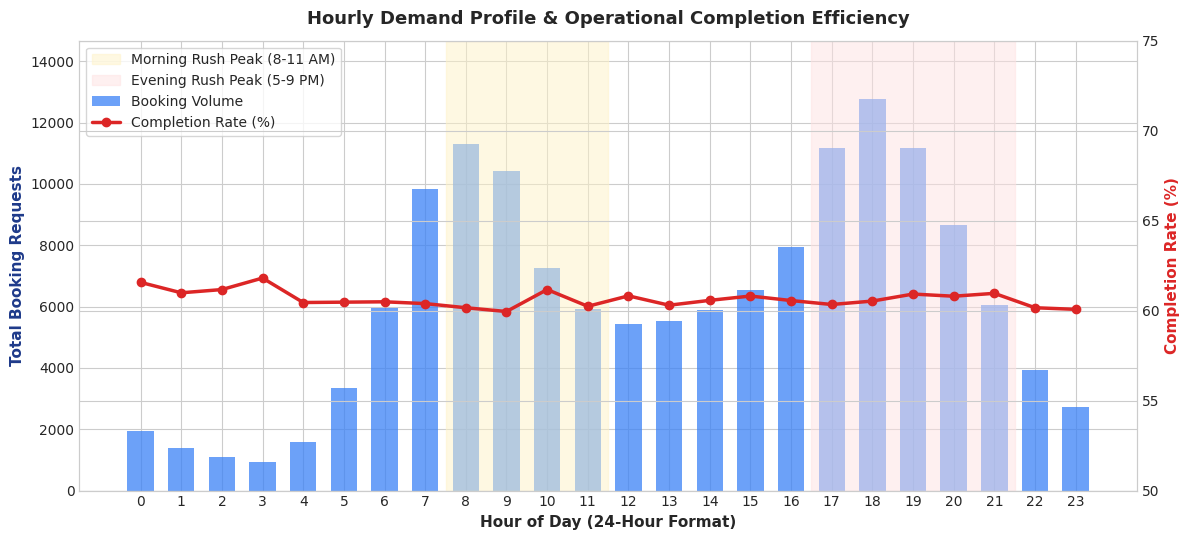

In [2]:
query_1 = """
SELECT 
    booking_hour,
    COUNT(*) AS total_bookings,
    ROUND(100.0 * SUM(CASE WHEN booking_status = 'Completed' THEN 1 ELSE 0 END) / COUNT(*), 2) AS completion_rate_pct,
    ROUND(AVG(customer_wait_time), 2) AS avg_vtat_min
FROM uber_features
GROUP BY booking_hour
ORDER BY booking_hour ASC;
"""
df_1 = pd.read_sql_query(query_1, conn)

fig, ax1 = plt.subplots(figsize=(12, 5.5))
ax2 = ax1.twinx()

bars = ax1.bar(df_1['booking_hour'], df_1['total_bookings'], color='#3B82F6', alpha=0.75, width=0.65, label='Booking Volume')
line = ax2.plot(df_1['booking_hour'], df_1['completion_rate_pct'], color='#DC2626', linewidth=2.5, marker='o', label='Completion Rate (%)')

ax1.axvspan(7.5, 11.5, color='#FEF3C7', alpha=0.5, label='Morning Rush Peak (8-11 AM)')
ax1.axvspan(16.5, 21.5, color='#FEE2E2', alpha=0.5, label='Evening Rush Peak (5-9 PM)')

ax1.set_xlabel('Hour of Day (24-Hour Format)', fontsize=11, fontweight='bold')
ax1.set_ylabel('Total Booking Requests', fontsize=11, fontweight='bold', color='#1E3A8A')
ax2.set_ylabel('Completion Rate (%)', fontsize=11, fontweight='bold', color='#DC2626')
ax1.set_xticks(range(0, 24))
ax1.set_ylim(0, df_1['total_bookings'].max() * 1.15)
ax2.set_ylim(50, 75)

plt.title('Hourly Demand Profile & Operational Completion Efficiency', fontsize=13, fontweight='bold', pad=12)

lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left', frameon=True)

plt.tight_layout()
plt.show()


## 2. Modal Fulfillment & Friction Breakdown by Vehicle Segment
**Business Question**: Which vehicle types have higher completion rates versus driver or customer drop-offs?

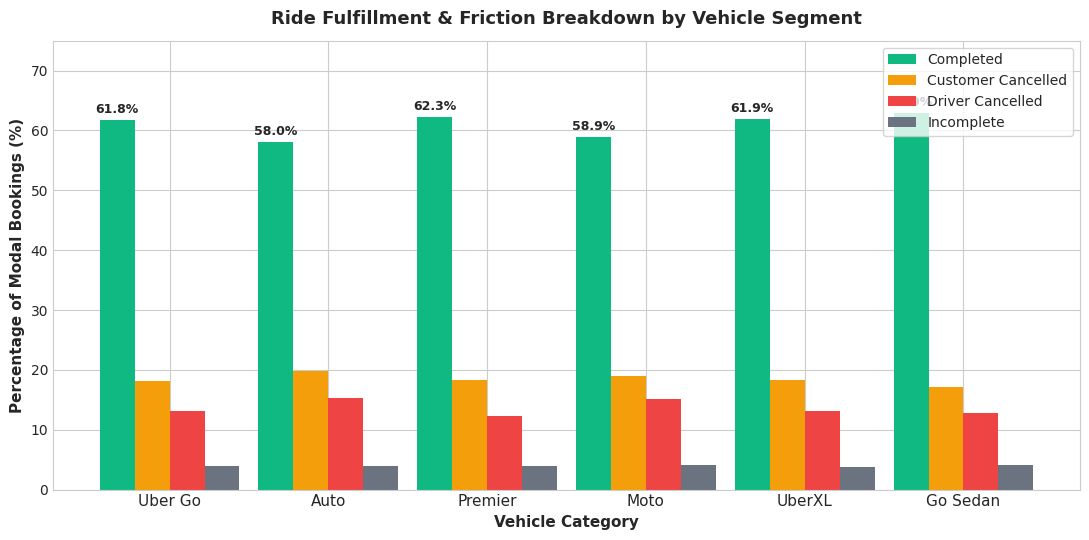

In [3]:
query_2 = """
SELECT 
    vehicle_type,
    COUNT(*) AS total_bookings,
    ROUND(100.0 * SUM(CASE WHEN booking_status = 'Completed' THEN 1 ELSE 0 END) / COUNT(*), 2) AS completion_rate,
    ROUND(100.0 * SUM(customer_cancellation) / COUNT(*), 2) AS customer_cancel_rate,
    ROUND(100.0 * SUM(driver_cancellation) / COUNT(*), 2) AS driver_cancel_rate,
    ROUND(100.0 * SUM(incomplete_rides) / COUNT(*), 2) AS incomplete_rate
FROM uber_features
GROUP BY vehicle_type
ORDER BY total_bookings DESC;
"""
df_2 = pd.read_sql_query(query_2, conn)

fig, ax = plt.subplots(figsize=(11, 5.5))
x = np.arange(len(df_2['vehicle_type']))
width = 0.22

rects1 = ax.bar(x - width*1.5, df_2['completion_rate'], width, label='Completed', color='#10B981')
rects2 = ax.bar(x - width*0.5, df_2['customer_cancel_rate'], width, label='Customer Cancelled', color='#F59E0B')
rects3 = ax.bar(x + width*0.5, df_2['driver_cancel_rate'], width, label='Driver Cancelled', color='#EF4444')
rects4 = ax.bar(x + width*1.5, df_2['incomplete_rate'], width, label='Incomplete', color='#6B7280')

ax.set_ylabel('Percentage of Modal Bookings (%)', fontsize=11, fontweight='bold')
ax.set_xlabel('Vehicle Category', fontsize=11, fontweight='bold')
ax.set_title('Ride Fulfillment & Friction Breakdown by Vehicle Segment', fontsize=13, fontweight='bold', pad=12)
ax.set_xticks(x)
ax.set_xticklabels(df_2['vehicle_type'], fontsize=11)
ax.legend(loc='upper right', frameon=True)
ax.set_ylim(0, 75)

for rect in rects1:
    height = rect.get_height()
    ax.annotate(f'{height:.1f}%', xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


## 3. Monthly Demand Trajectory & Top-Line Revenue Seasonality
**Business Question**: How do ride volume and completed gross booking value trend across the 12 calendar months?

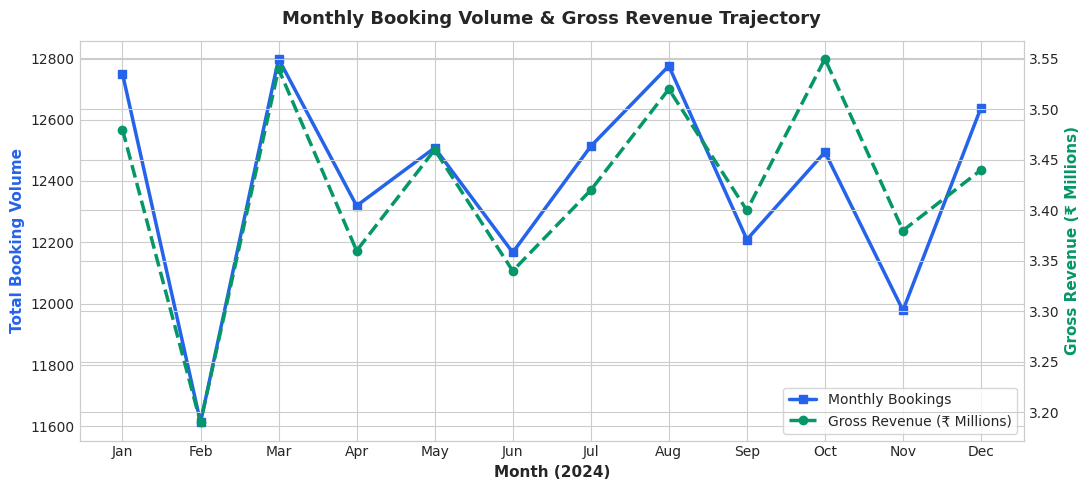

In [4]:
query_3 = """
SELECT 
    month,
    COUNT(*) AS total_bookings,
    ROUND(SUM(CASE WHEN booking_status = 'Completed' THEN booking_value ELSE 0 END) / 1000000.0, 2) AS revenue_millions_inr
FROM uber_features
GROUP BY month
ORDER BY CAST(month AS INTEGER) ASC;
"""
df_3 = pd.read_sql_query(query_3, conn)

fig, ax1 = plt.subplots(figsize=(11, 5))
ax2 = ax1.twinx()

month_labels = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
ax1.plot(month_labels, df_3['total_bookings'], color='#2563EB', linewidth=2.5, marker='s', label='Monthly Bookings')
ax2.plot(month_labels, df_3['revenue_millions_inr'], color='#059669', linewidth=2.5, marker='o', linestyle='--', label='Gross Revenue (₹ Millions)')

ax1.set_xlabel('Month (2024)', fontsize=11, fontweight='bold')
ax1.set_ylabel('Total Booking Volume', fontsize=11, fontweight='bold', color='#2563EB')
ax2.set_ylabel('Gross Revenue (₹ Millions)', fontsize=11, fontweight='bold', color='#059669')

plt.title('Monthly Booking Volume & Gross Revenue Trajectory', fontsize=13, fontweight='bold', pad=12)

lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='lower right', frameon=True)

plt.tight_layout()
plt.show()


## 4. Top Urban Pickup Hotspots by Mobility Demand Volume
**Business Question**: Which urban pickup locations generate the highest ride requests and volume share?

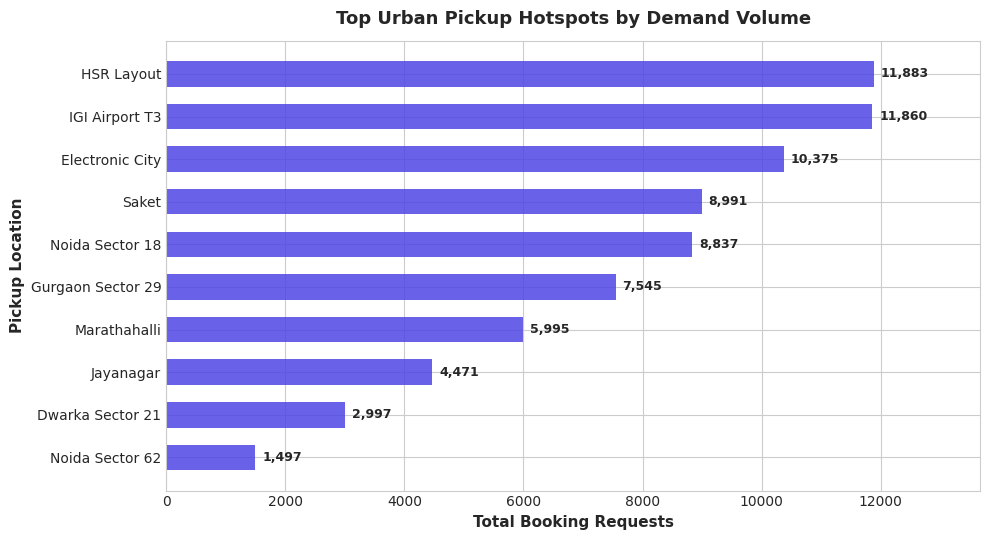

In [5]:
query_4 = """
SELECT 
    pickup_location,
    COUNT(*) AS total_bookings
FROM uber_features
GROUP BY pickup_location
ORDER BY total_bookings ASC
LIMIT 10;
"""
df_4 = pd.read_sql_query(query_4, conn)

fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.barh(df_4['pickup_location'], df_4['total_bookings'], color='#4F46E5', alpha=0.85, height=0.6)

ax.set_xlabel('Total Booking Requests', fontsize=11, fontweight='bold')
ax.set_ylabel('Pickup Location', fontsize=11, fontweight='bold')
ax.set_title('Top Urban Pickup Hotspots by Demand Volume', fontsize=13, fontweight='bold', pad=12)

for bar in bars:
    width = bar.get_width()
    ax.annotate(f'{int(width):,}', xy=(width, bar.get_y() + bar.get_height() / 2),
                xytext=(5, 0), textcoords="offset points", ha='left', va='center', fontsize=9, fontweight='bold')

ax.set_xlim(0, df_4['total_bookings'].max() * 1.15)
plt.tight_layout()
plt.show()


## 5. Vehicle Segment Unit Economics: Average Fare vs. Trip Distance
**Business Question**: How do average booking values and trip distances differ across entry, standard, and premium vehicle tiers?

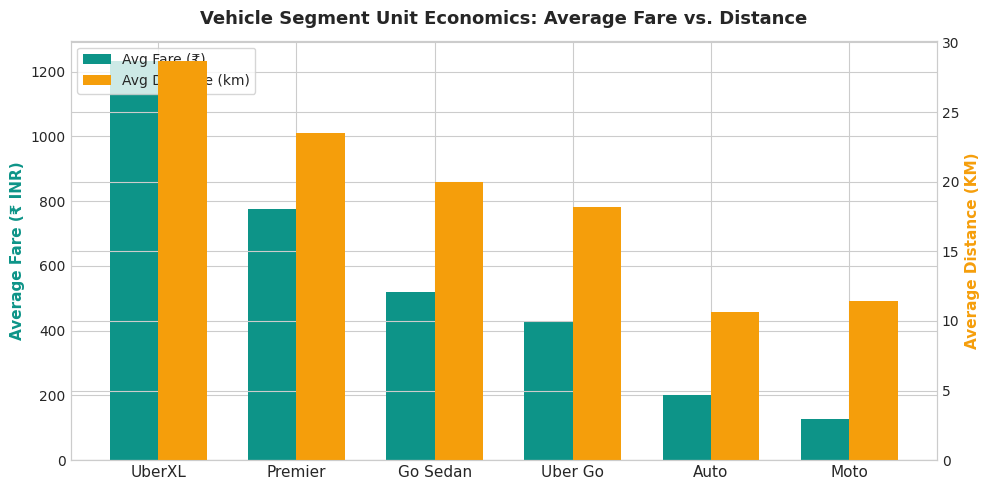

In [6]:
query_5 = """
SELECT 
    vehicle_type,
    ROUND(AVG(CASE WHEN booking_status = 'Completed' THEN booking_value END), 2) AS avg_booking_value,
    ROUND(AVG(CASE WHEN booking_status = 'Completed' THEN ride_distance END), 2) AS avg_distance_km
FROM uber_features
GROUP BY vehicle_type
ORDER BY avg_booking_value DESC;
"""
df_5 = pd.read_sql_query(query_5, conn)

fig, ax1 = plt.subplots(figsize=(10, 5))
ax2 = ax1.twinx()

x = np.arange(len(df_5['vehicle_type']))
width = 0.35

ax1.bar(x - width/2, df_5['avg_booking_value'], width, label='Avg Fare (₹)', color='#0D9488')
ax2.bar(x + width/2, df_5['avg_distance_km'], width, label='Avg Distance (km)', color='#F59E0B')

ax1.set_xticks(x)
ax1.set_xticklabels(df_5['vehicle_type'], fontsize=11)
ax1.set_ylabel('Average Fare (₹ INR)', fontsize=11, fontweight='bold', color='#0D9488')
ax2.set_ylabel('Average Distance (KM)', fontsize=11, fontweight='bold', color='#F59E0B')

plt.title('Vehicle Segment Unit Economics: Average Fare vs. Distance', fontsize=13, fontweight='bold', pad=12)

lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left', frameon=True)

plt.tight_layout()
plt.show()


## 6. Root Cause Breakdown: Stated Cancellation Motivations
**Business Question**: What are the top customer-stated reasons versus driver-stated reasons for ride cancellations?

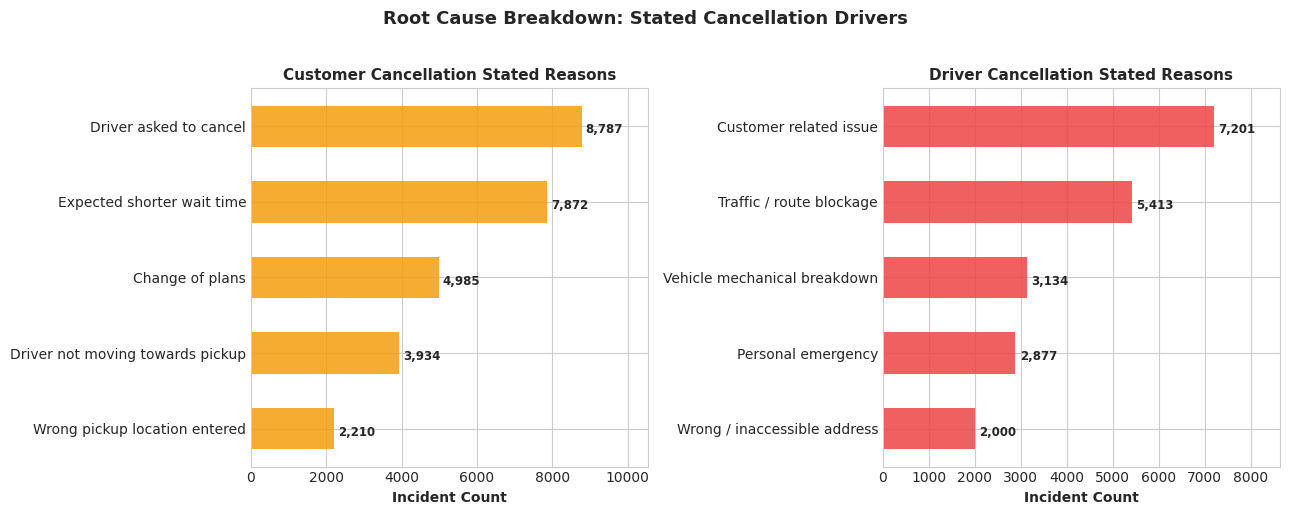

In [7]:
query_6_cust = """
SELECT customer_cancellation_reason AS reason, COUNT(*) AS count
FROM uber_features
WHERE customer_cancellation = 1 AND customer_cancellation_reason IS NOT NULL
GROUP BY customer_cancellation_reason;
"""
query_6_driv = """
SELECT driver_cancellation_reason AS reason, COUNT(*) AS count
FROM uber_features
WHERE driver_cancellation = 1 AND driver_cancellation_reason IS NOT NULL
GROUP BY driver_cancellation_reason;
"""
df_6_cust = pd.read_sql_query(query_6_cust, conn).sort_values('count', ascending=True)
df_6_driv = pd.read_sql_query(query_6_driv, conn).sort_values('count', ascending=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

ax1.barh(df_6_cust['reason'], df_6_cust['count'], color='#F59E0B', alpha=0.85, height=0.55)
ax1.set_title('Customer Cancellation Stated Reasons', fontsize=11, fontweight='bold')
ax1.set_xlabel('Incident Count', fontsize=10, fontweight='bold')
for p in ax1.patches:
    ax1.annotate(f"{int(p.get_width()):,}", (p.get_width() + 100, p.get_y() + 0.18), fontsize=8.5, fontweight='bold')
ax1.set_xlim(0, df_6_cust['count'].max() * 1.2)

ax2.barh(df_6_driv['reason'], df_6_driv['count'], color='#EF4444', alpha=0.85, height=0.55)
ax2.set_title('Driver Cancellation Stated Reasons', fontsize=11, fontweight='bold')
ax2.set_xlabel('Incident Count', fontsize=10, fontweight='bold')
for p in ax2.patches:
    ax2.annotate(f"{int(p.get_width()):,}", (p.get_width() + 100, p.get_y() + 0.18), fontsize=8.5, fontweight='bold')
ax2.set_xlim(0, df_6_driv['count'].max() * 1.2)

plt.suptitle('Root Cause Breakdown: Stated Cancellation Drivers', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 7. Customer Satisfaction Rating vs. Dispatch Arrival Time (VTAT)
**Business Question**: How does customer satisfaction degrade as driver arrival wait time (VTAT) increases?

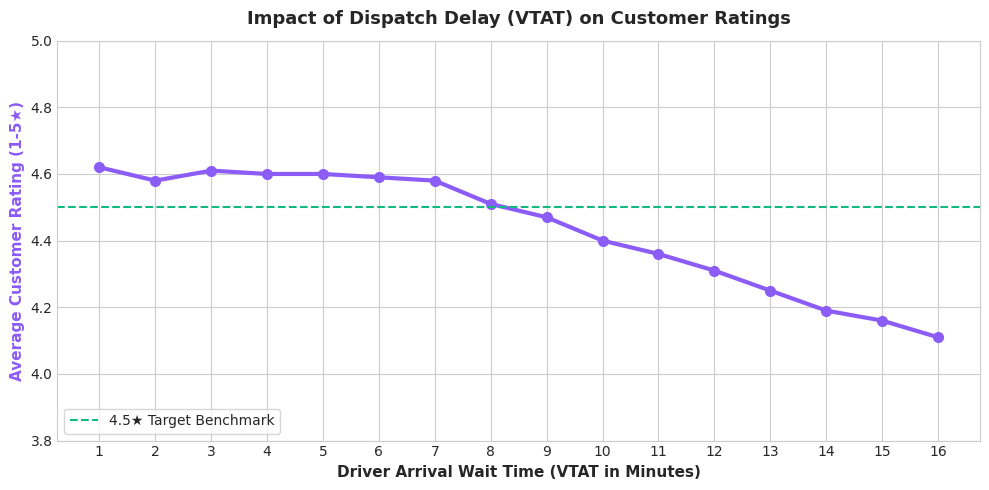

In [8]:
query_7 = """
SELECT 
    ROUND(customer_wait_time, 0) AS wait_time_bin,
    ROUND(AVG(customer_rating), 2) AS avg_customer_rating,
    COUNT(*) AS trip_count
FROM uber_features
WHERE customer_rating IS NOT NULL AND customer_wait_time BETWEEN 1 AND 18
GROUP BY ROUND(customer_wait_time, 0)
HAVING COUNT(*) > 50
ORDER BY wait_time_bin ASC;
"""
df_7 = pd.read_sql_query(query_7, conn)

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(df_7['wait_time_bin'], df_7['avg_customer_rating'], color='#8B5CF6', linewidth=3.0, marker='o', markersize=7)
ax1.axhline(4.5, color='#10B981', linestyle='--', label='4.5★ Target Benchmark')

ax1.set_xlabel('Driver Arrival Wait Time (VTAT in Minutes)', fontsize=11, fontweight='bold')
ax1.set_ylabel('Average Customer Rating (1-5★)', fontsize=11, fontweight='bold', color='#8B5CF6')
ax1.set_xticks(df_7['wait_time_bin'])
ax1.set_ylim(3.8, 5.0)

plt.title('Impact of Dispatch Delay (VTAT) on Customer Ratings', fontsize=13, fontweight='bold', pad=12)
ax1.legend(loc='lower left', frameon=True)

plt.tight_layout()
plt.show()

conn.close()
